# Прогнозирование временных рядов (регресионные  машиного обучения)
Прогнозирование временных рядов означает продолжение данных прошлых периодов в будущее, где эти значения еще не доступны. Прогнозирование обычно выполняется для оптимизации таких областей как уровень товарных запасов, производственных мощностей и количества персонала.

В определении временных рядов есть две основные структурные переменные:

* Период, который представляет уровень обобщения. Наиболее часто используемыми периодами являются: месяц, неделя, день в цепях поставок (для оптимизации товарных запасов). Колл-центры обычно ориентируются на период в 15 минут (для оптимизации количества персонала).
* Горизонт, который представляет количество периодов в будущем, на которое необходим прогноз. В цепях поставок горизонт обычно равен или превышает срок поставки.
Данная лабораторная работа посвящена прогнозрованию энергопотребления по данным, собранным за 11 лет. Тренировочная выборка состоит из 10 лет, тестовая из одного года.

**Цель:**

Разработка и оценка регрессионных моделей машинного обучения для прогнозирования временных рядов энергопотребления.

**Ход работы (представлен программно далее):**

1.  Загрузить, инициализировать и проанализировать набор данных по энергопотреблению.
2.  Подготовить временные признаки для анализа временных рядов.
3.  Визуализировать данные временных рядов и проанализировать их характеристики, включая автокорреляцию и тренды.
4.  Реализовать и оценить различные алгоритмы регрессионного машинного обучения для прогнозирования энергопотребления.


# Лаборатоное задание

1. Изучить содержание интерактивного блокнота;

2. Произвести оценку точности прогнозной модели при изменении размера тестовой выборки датасета (Составить таблицу в которой отражается зависимость точности метрик модели МО (R2, RMSE, MAE, MSE)) от прогнозного диапазона (необходимо изменять размер тестовой выборки от 1 до 12 месяцев) для всех представленных в работе алгоритмов МО, построить графики получившихся завивимостей;

3.  Изучить структуру библиотеки sklearn (https://scikit-learn.org/stable/)  и выполнить задачу прогнозирования с использованием любого регрессионного алгоритма машинного обучения из библиотеки sklearn. Прогнозный период 1 год.


## Загрузка, инициализация и анализ данных

In [ ]:
# Команда импорта сторонних библиотек (import 'название библиотеки' as 'сокращенное название')
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ссылка на датасет
url='https://raw.githubusercontent.com/jenfly/opsd/master/opsd_germany_daily.csv'
# Операция присваивания переменной data датафрейма (дф), который формируется на основе датасета
data = pd.read_csv(url, sep=",")
data # Вывод полученного дф (рабоатет только в интерактивных блокнотаз (colab, jupiter))

,Date,Consumption,Wind,Solar,Wind+Solar
0,2006-01-01,1069.18400,NaN,NaN,NaN
1,2006-01-02,1380.52100,NaN,NaN,NaN
2,2006-01-03,1442.53300,NaN,NaN,NaN
3,2006-01-04,1457.21700,NaN,NaN,NaN
4,2006-01-05,1477.13100,NaN,NaN,NaN
...,...,...,...,...,...
4378,2017-12-27,1263.94091,394.507,16.530,411.037
4379,2017-12-28,1299.86398,506.424,14.162,520.586
4380,2017-12-29,1295.08753,584.277,29.854,614.131
4381,2017-12-30,1215.44897,721.247,7.467,728.714


Базовые библиотеки, которые могут использоваться при машинном обучении и анализе данных:
1. Pandas - Хранение, обработка и анализ датасетов (табличный формат, временые ряды)
2. Numpy - Хранение, обработка и анализ датасетов (многомерные массивы)
3. Sklearn - Библиотека машинного обуения
4. SciPy - Библиотека научных и инженерных рассчетов
5. Seaborn - Библиотека визуализации (построение графиков), основана на библ. matplotlib
6. Matplotlib - Библиотека визуализации

Графическая демонтрация всего обрабатываемого датасета атрибуты функции x_vars - значения оси абсцисс, data - датасет, height - высота графика (inch),aspect - длина графика

In [ ]:
# sns.pairplot(x_vars=['Date'], data = data, height=5, aspect=20)

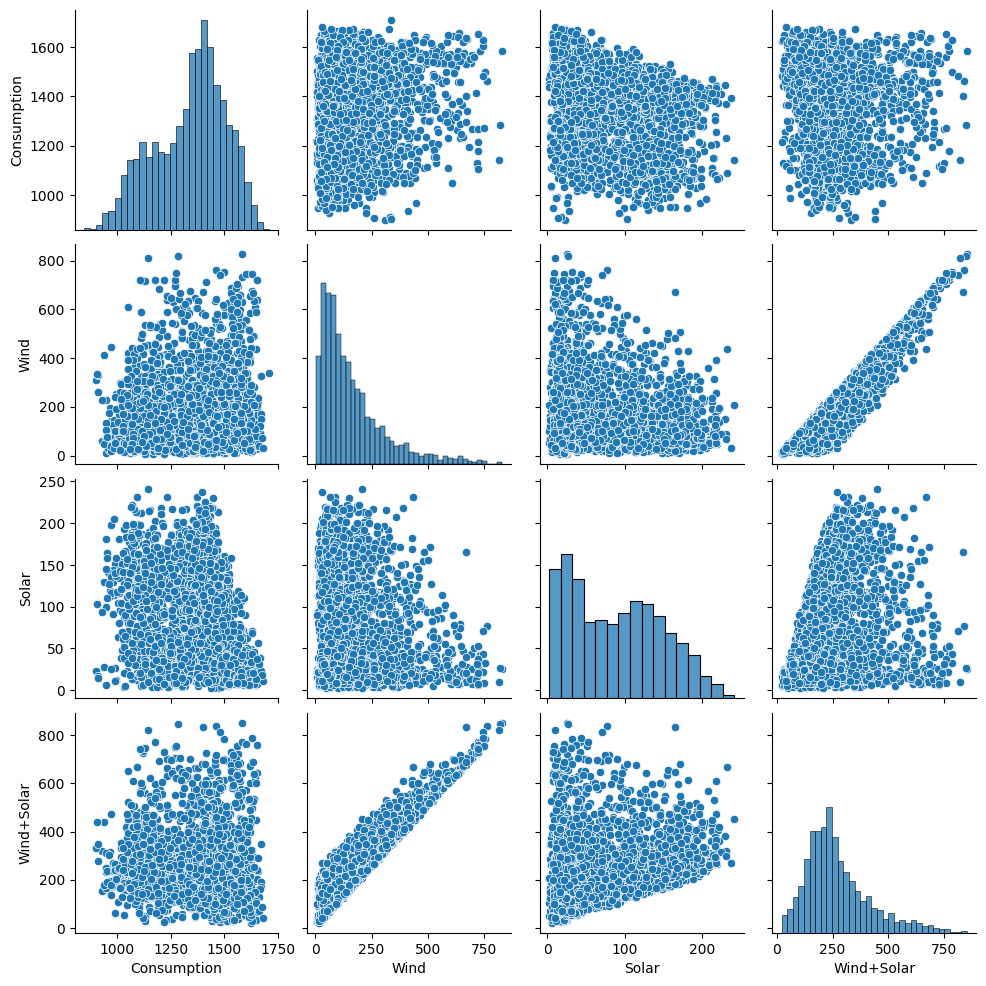

In [ ]:
sns.pairplot(data = data) # Матрица рассеяния (перекрестный анализ)

## Подготовка временных меток

In [ ]:

data['time'] = str('01:00:00') # Добавление временной составляющей
data['Date'] = pd.to_datetime(data['Date'].astype(str) + ' ' + data['time'].astype(str), format='%Y-%m-%d %H:%M:%S') # Формирование формата времени с датой
data

,Date,Consumption,Wind,Solar,Wind+Solar,time
0,2006-01-01 01:00:00,1069.18400,NaN,NaN,NaN,01:00:00
1,2006-01-02 01:00:00,1380.52100,NaN,NaN,NaN,01:00:00
2,2006-01-03 01:00:00,1442.53300,NaN,NaN,NaN,01:00:00
3,2006-01-04 01:00:00,1457.21700,NaN,NaN,NaN,01:00:00
4,2006-01-05 01:00:00,1477.13100,NaN,NaN,NaN,01:00:00
...,...,...,...,...,...,...
4378,2017-12-27 01:00:00,1263.94091,394.507,16.530,411.037,01:00:00
4379,2017-12-28 01:00:00,1299.86398,506.424,14.162,520.586,01:00:00
4380,2017-12-29 01:00:00,1295.08753,584.277,29.854,614.131,01:00:00
4381,2017-12-30 01:00:00,1215.44897,721.247,7.467,728.714,01:00:00


In [ ]:
data = data.set_index('Date') # Перенос колонки 'Date' в качестве значений индексов дф
data

,Consumption,Wind,Solar,Wind+Solar,time
Date,,,,,
2006-01-01 01:00:00,1069.18400,NaN,NaN,NaN,01:00:00
2006-01-02 01:00:00,1380.52100,NaN,NaN,NaN,01:00:00
2006-01-03 01:00:00,1442.53300,NaN,NaN,NaN,01:00:00
2006-01-04 01:00:00,1457.21700,NaN,NaN,NaN,01:00:00
2006-01-05 01:00:00,1477.13100,NaN,NaN,NaN,01:00:00
...,...,...,...,...,...
2017-12-27 01:00:00,1263.94091,394.507,16.530,411.037,01:00:00
2017-12-28 01:00:00,1299.86398,506.424,14.162,520.586,01:00:00
2017-12-29 01:00:00,1295.08753,584.277,29.854,614.131,01:00:00


## Построение графика зависимости даты только от энергопотребления (библ.  `seaborn (sns)`)

<Axes: xlabel='Date', ylabel='Consumption'>

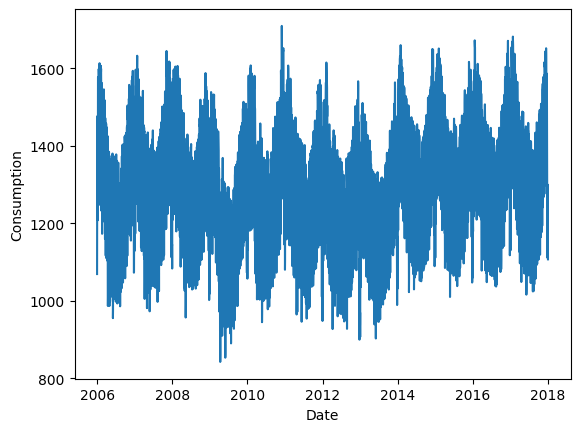

In [ ]:
sns.lineplot(data = data['Consumption'])

## Построение автокорреляционной функции (АКФ)

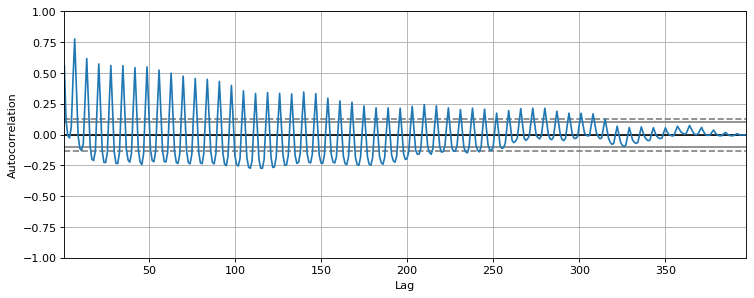

In [ ]:
plt.figure(figsize=(11,4), dpi= 80) # Инициализация подложки графика
# Построение АКФ средствами библиоткеи pandas (функции plotting и autocorrelation_plot)
# Функция .loc позволяет обратиться к группе строчек или колонок по
# соответствующим названиям индексов или названиям колонок.
# В примере ниже выбирается набор строк колонки 'Consumption' дф data в диапазоне даты
# от '2012-01' до '2013-01' и передается функции вычисления и построения АКФ.
pd.plotting.autocorrelation_plot(data.loc['2012-01': '2013-01', 'Consumption']);

## Блок построения временных трендов с усреднением по 7 и 365 дней по колонке 'Consumption'

Text(0.5, 1.0, 'Trends in Electricity Consumption')

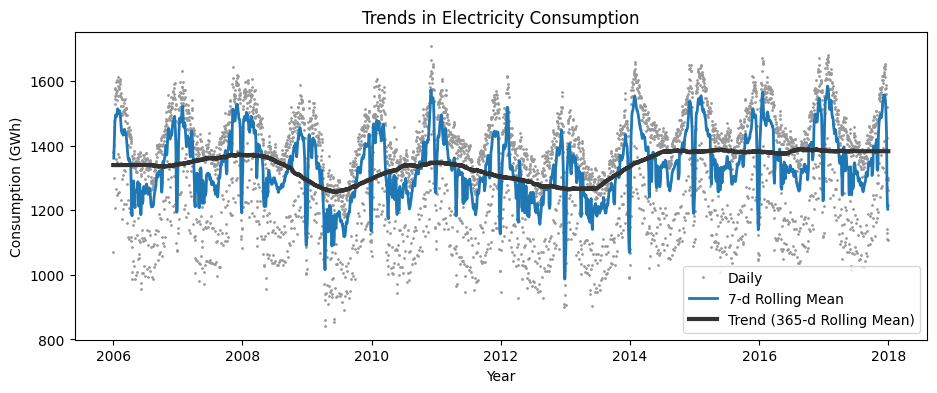

In [ ]:
data_columns = ['Consumption', 'Wind', 'Solar', 'Wind+Solar']

# data_365d_rol - название дф, в который заносятся колонки с усреднением за 365 дней (функции rolling() и mean())
data_365d_rol = data[data_columns].rolling(window = 365, center = True).mean()
# data_7d_rol - название дф, в который заносятся колонки с усреднением за 7 дней (функции rolling() и mean())
data_7d_rol = data[data_columns].rolling(window = 7, center = True).mean()

data_365d_rol['Consumption'] = data_365d_rol['Consumption'].fillna(method = 'bfill').fillna(method = 'ffill')

# Построение графика с помощью библиотеки matplitlib (plt)
fig, ax = plt.subplots(figsize = (11,4)) # Инициализация графика fig - подложка (холст), ax - оси
# Построение колонки 'Consumption' дф data, через запятую передаются атрибуты для настройки графика
# marker - маркер точки на графике, markersize -  размер маркера, color - цвет,
# linestyle - тип линии (если используется),
# label - подпись графика (не заголовок, отображается функцией legend())
ax.plot(data['Consumption'], marker='.', markersize=2, color='0.6', linestyle='None', label='Daily')
# Построение колонки 'Consumption' дф data_7d_rol
ax.plot(data_7d_rol['Consumption'], linewidth=2, label='7-d Rolling Mean')
# Построение колонки 'Consumption' дф data_365d_rol
ax.plot(data_365d_rol['Consumption'], color='0.2', linewidth=3, label='Trend (365-d Rolling Mean)')
# Добваление на график таблички (права низ) с названиями графиков
ax.legend()
# Добавление названия оси абсцисс
ax.set_xlabel('Year')
# Добавление названия оси ординат
ax.set_ylabel('Consumption (GWh)')
# Добавление названия всего графика
ax.set_title('Trends in Electricity Consumption')

## Формирование функции вычисления точности прогнозной модели

In [ ]:
import sklearn.metrics as metrics # Импорт библиотеки по рассчету метрик ошибки
import numpy as np

# def - инициализация функции, далее идет название и передаваемые атрибуты
# y_true - исходный дф, y_pred - спрогнозированный дф, model - название
# модели машинного обучения
def regression_results(y_true, y_pred, model):
    # Метрики регресионных моделей
    # Средняя абсолютная ошибка
    mean_absolute_error = metrics.mean_absolute_error(y_true, y_pred)
    # Средняя квадратичная ошибка
    mse = metrics.mean_squared_error(y_true, y_pred)
    # Медианная вбсолютная ошибка
    median_absolute_error = metrics.median_absolute_error(y_true, y_pred)
    # Коэффициент детерминации (R^2) - определяет степень соответствия
    # полученной в ходе МО модели исходным данным. (Модели с коэфф. детерм.
    # более 0,8 (80%) считаются достаточно точными)
    r2 = metrics.r2_score(y_true, y_pred)

    # Вывод вычисленных метрик
    print('-------------------------------------------------------')
    print(model)
    # print('explained_variance: ', round(explained_variance,4))
    # print('mean_squared_log_error: ', round(mean_squared_log_error,4))
    print('r2: ', round(r2,4))
    print('MAE: ', round(mean_absolute_error,4))
    print('MSE: ', round(mse,4))
    print('RMSE: ', round(np.sqrt(mse),4))


# Реализации алгоритмов машинного обучения
В данном блоке представлены регресионные алгоритмы машинного обучения:
1. `LinearRegression` - линейная ргерессия;
2. `RandomForestRegressor` - регрессия случайного леса;
3. `KNeighborsRegressor` - регрессия по типу к - соседних;
4. `SVR` (Support Vector Machine) - машина опорных векторов;
5. `MLPRegressor` (Multi-layer Perceptron regressor) - многослойная нейронная сеть по типу перцептрона.

Целью является произвести прогнозирование временного ряда 'Consumption' (энергопотребление). Для этого необходимо произвести тренировку модели МО по данным дф `data['Consumption']`, т.е. использовать в качестве изменяемой величины значение энергопотребления, а неизменяемой - время. Чтобы провести дальнейшую оценку точности обученной модели исходный датасет в начале делится на две части - тренировочную (`X_train` и `y_train`) и тестовую (`X_test` и `y_test`), где к переменной X относится неизменяемая составляющая (пр. время и ее составляющие), а к y - изменяемая, т.е. в текущем случае значения энергопотребления (дф  `data['Consumption']`). Проверка обученной модели выполняется при помощи функции `regression_results()`, которая возвращает набор различных метрик оценки точности обученной модели. Строятся графики сравнения реального временного хода значений энергопотребления `y_test` и спрогнозированног (`y_pred`) на идентичный период времени.

LR: 0.343747 (0.029773)
NN: 0.479094 (0.167363)
KNN: 0.646307 (0.083185)
RF: 0.633648 (0.085163)
SVR: -0.117944 (0.157755)


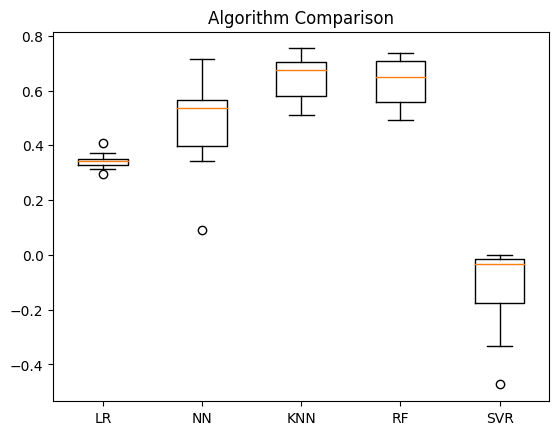

-------------------------------------------------------
LinearRegression()
r2:  0.3802
MAE:  104.2855
MSE:  16785.2379
RMSE:  129.5579


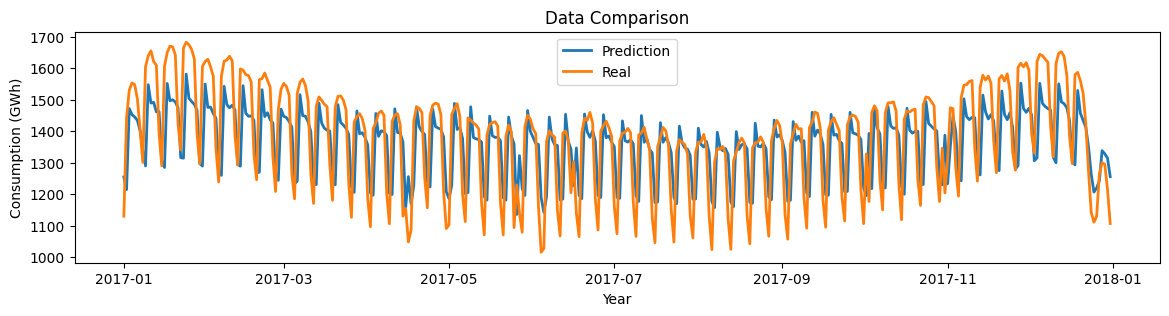

-------------------------------------------------------
MLPRegressor(solver='lbfgs')
r2:  0.5697
MAE:  80.0406
MSE:  11651.6305
RMSE:  107.9427


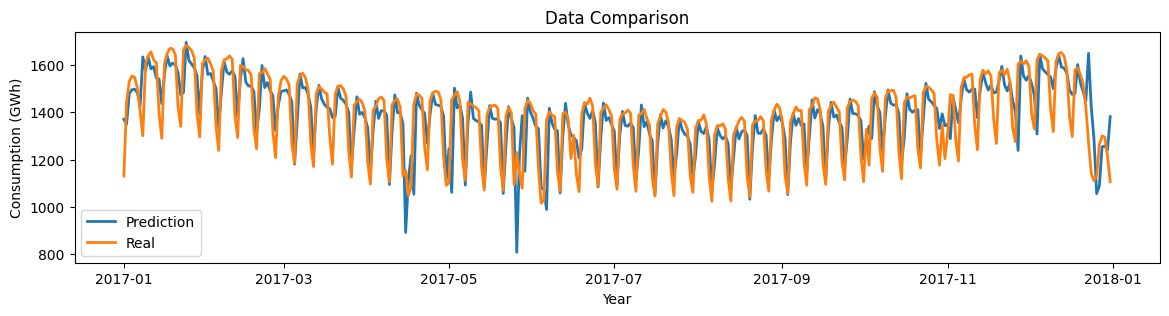

-------------------------------------------------------
KNeighborsRegressor()
r2:  0.7109
MAE:  53.5502
MSE:  7830.2964
RMSE:  88.489


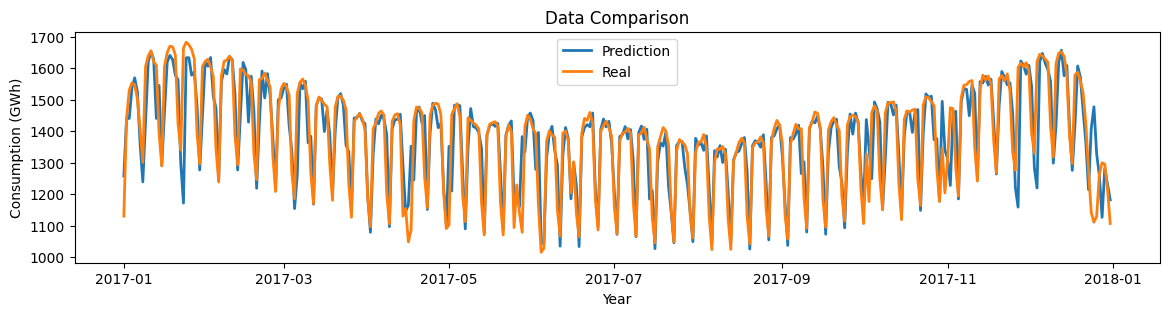

-------------------------------------------------------
RandomForestRegressor(n_estimators=50)
r2:  0.6773
MAE:  57.2271
MSE:  8738.235
RMSE:  93.4785


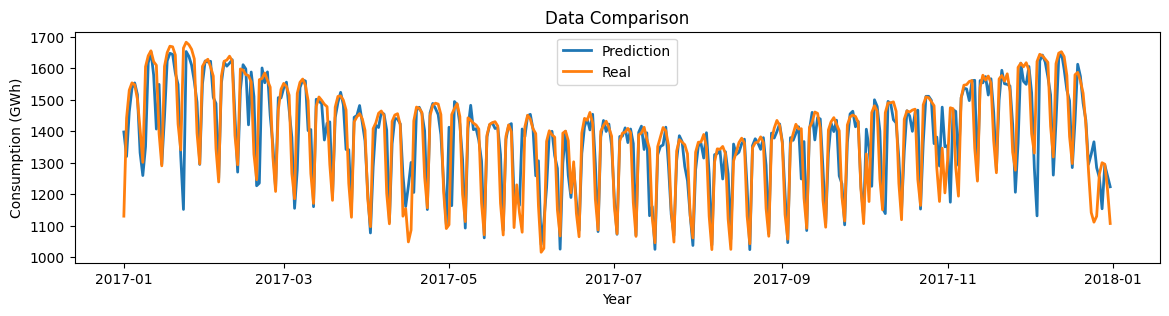

-------------------------------------------------------
SVR(gamma='auto')
r2:  -0.0134
MAE:  136.5488
MSE:  27442.8101
RMSE:  165.6587


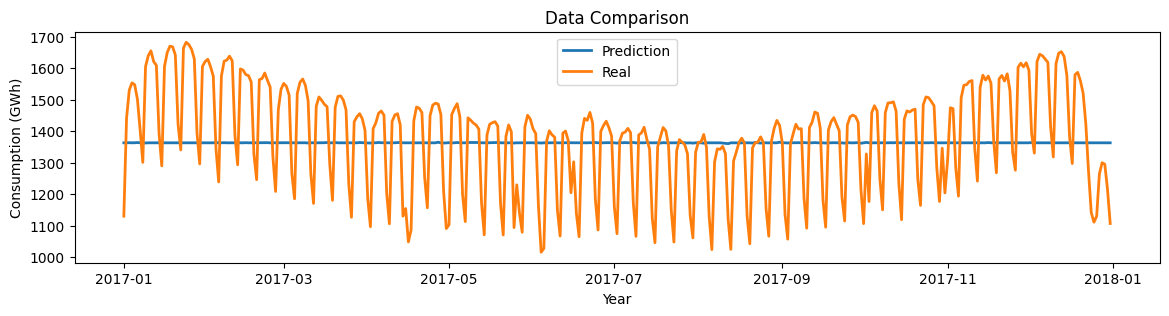

In [ ]:
import warnings
warnings.filterwarnings('ignore')
# Импорт библиотеки деления датасета на выборки (TimeSeriesSplit) и перекрестного анализа (cross_val_score)
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
# Импорт библиотек МО
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

# Копирование исхолного дф
data_consumption = data[['Consumption']].copy()
# Добавление новой колонки со вчерашними значениями (сдвиг колонки 'Consumption' на шаг назад)
data_consumption.loc[:,'Yesterday'] = data_consumption.loc[:,'Consumption'].shift()
# Добавление колонки с разностью между значениями одно и двух дневной давности
data_consumption.loc[:,'Yesterday_Diff'] = data_consumption.loc[:,'Yesterday'].diff()
# Удаление из дф значений NaN
data_consumption = data_consumption.dropna()

# Формаирование тренировочнйо части датасета
X_train = data_consumption[:'2016'].drop(['Consumption'], axis = 1)
y_train = data_consumption.loc[:'2016', 'Consumption']
# Формирование тестовой части датасета
X_test = data_consumption['2017-01':'2017-12'].drop(['Consumption'], axis = 1)
y_test = data_consumption.loc['2017-01':'2017-12', 'Consumption']

# Объявление алгоритмов МО и аккумуляция их в массив
# для удобной работы в цикле
models = [] # Лист для хранения моделей
models.append(('LR', LinearRegression()))
models.append(('NN', MLPRegressor(solver = 'lbfgs')))  # solver - определение ядра принятия решений
models.append(('KNN', KNeighborsRegressor()))
models.append(('RF', RandomForestRegressor(n_estimators = 50))) # n_estimators - число деревьев в ансамбле
models.append(('SVR', SVR(gamma='auto', kernel='rbf'))) # kernel - ядро по которому формируется опорный вектор
# Рассчетный цикл
results = [] # Лист для хранения результата оценки модели
names = [] # Лист для хранения имени модели
# Начало цикла for
for name, model in models:
  # TimeSeriesSplit определяет количество частей на которые будет разбит датасет,
  # переменная tscv используется как атрибут функции cross_val_score(), т.е.
  # определяет количество частей датасета по которым будет проведен перекрестный
  # анализ (валидация результатов по метрике R^2)
  tscv = TimeSeriesSplit(n_splits=10)
  cv_results = cross_val_score(model, X_train, y_train, cv=tscv, scoring='r2')
  # Добавление результатов в лист results и names
  results.append(cv_results)
  names.append(name)
  # Вывод результатов
  print('%s: %f (%f)' % (name, cv_results.mean(), cv_results.std()))

# График сравнения используемых алгоритмов
plt.boxplot(results, labels=names)
plt.title('Algorithm Comparison')
plt.show()

# Цикл выполнения прогноза и сравнения реального временого хода
# со спрогнозированный результатом
for name, model in models:
  # Функция .fit() выполняет обучение модели (подгонку)
  # на основе тренировочного набора данных
  model = model.fit(X_train, y_train)
  # Функция .predict() выполняет прогнозирование
  # на основе тестового промежутка времени.
  y_pred = model.predict(X_test)
  # Далее выполняется передача результатов
  # прогнозирования y_pred и реального временного
  # хода y_test в функцию regression_results(), с целью
  # оценки точности итоговой модели.
  regression_results(y_test, y_pred, model)

  # Построение графика спрогнозированного и реальных временных ходов.
  fig, ax = plt.subplots(figsize = (14,3))
  ax.plot(X_test.index, y_pred, linewidth=2, label='Prediction')
  ax.plot(X_test.index, y_test, linewidth=2, label='Real')
  ax.set_title('Data Comparison')
  ax.legend()
  ax.set_xlabel('Year')
  ax.set_ylabel('Consumption (GWh)')
  plt.show()

Пояснение к графику сравнения результатов моделей

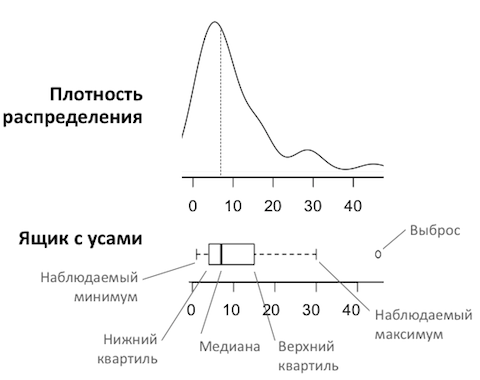

# Корректировки стационарности временного ряда, улучшение точности прогнозирования
Цель - повышение точности прогнозирования. Корректировка стационраности - такое изменение временого хода исследуемого набора данных, при котором его среднее значение не изменяется во времени (Параметры математического ожидания и дисперсии постоянны).

## Блок корректировки стационарности временного ряда

Text(0, 0.5, 'Consumption (GWh)')

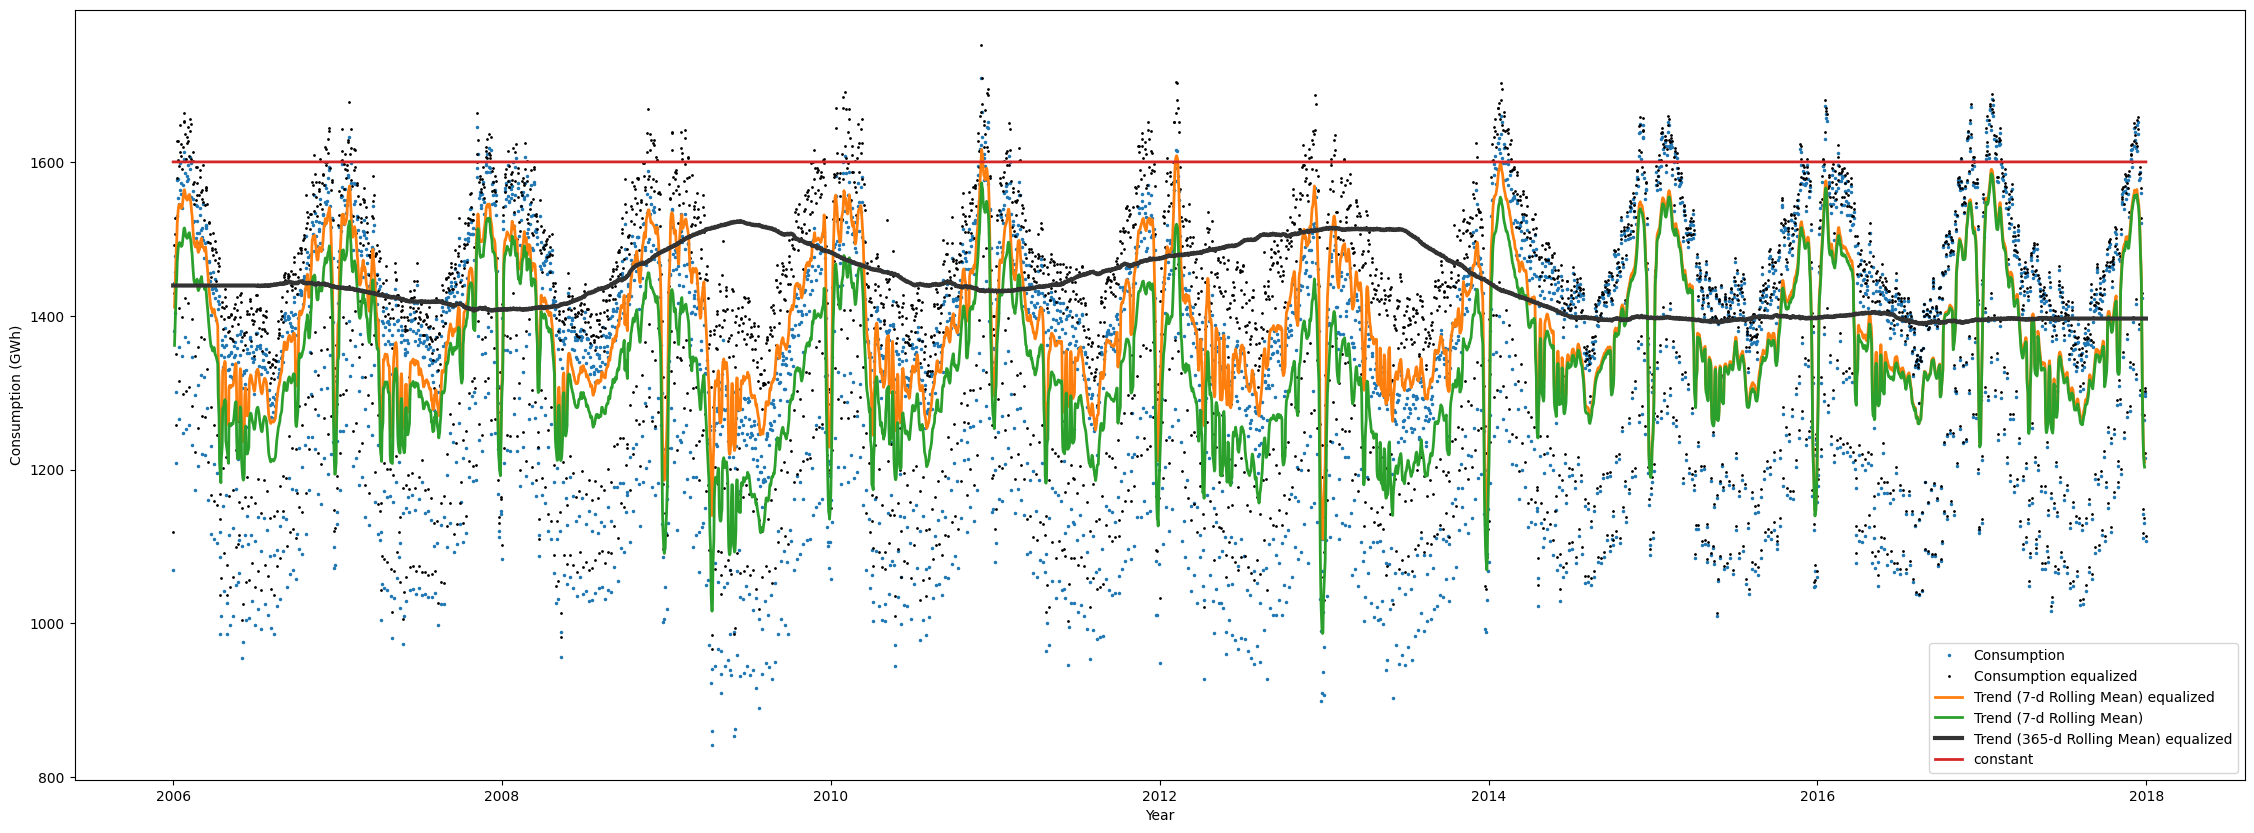

In [ ]:
# Копирование исходного дф data в дф data_correction для дальнейшего изменения
data_correction = data[data_columns].copy()

# Формирование новой колонки 'trend_residuals' дф data_correction в который заносится
# разность максимального значения годового тренда и каждого отсчета данного тренда
# с целью определения отклонения значений данного временного ряда (data_365d_rol['Consumption'])
# от его максималього значения. Полученные таким образом поправки будут ипользоваться в дальнейшем
# для выравнивания уровней амплитуды исследуемого временного хода (data['Consumption']).
data_correction['trend_residuals'] = data_365d_rol['Consumption'].max() - data_365d_rol['Consumption']
# Формирование скорректированного временного хода (data['Consumption']). В колонке 'Consumption_eq'
# (eq - equalized (выровненый)) заносится скорректированный ряд data_correction['Consumption'],
# коррекция которого выполнена путем прибавления вычесленных отклонения на основе линии тренда.
data_correction['Consumption_eq'] = data_correction['Consumption'] + data_correction['trend_residuals']
# Формирование тренда, в соответствие с которым выполнены поправки амплитуды
# временного хода (data['Consumption']) с целью графической визуализации поправок.
data_correction['trend_eq'] = data_365d_rol['Consumption'] + data_correction['trend_residuals'] * 2
# Фомирование тренда по выровненному временному ходу data_correction['Consumption_eq'].
data_correction['Consumption_eq_roll_7_day'] = data_correction['Consumption_eq'].rolling(window = 7, center = True).mean()
# Формирование дф с постоянным знаяением для гафичекой визуализации.
data_correction['constant'] = 1600

# Построение графиков
fig, ax = plt.subplots(figsize = (28,10))
# Исходный временной ряд
ax.plot(data_correction['Consumption'], marker='.', markersize=3,linestyle='None', label='Consumption')
# Выровненный временной ряд
ax.plot(data_correction['Consumption_eq'], marker='.', markersize=2, color='0',linestyle='None', label='Consumption equalized')
# Выровненный тренд с усреднением по 7 дней
ax.plot(data_correction['Consumption_eq_roll_7_day'], linewidth=2, label='Trend (7-d Rolling Mean) equalized')
# Исходный тренд с усреднением по 7 дней
ax.plot(data_7d_rol['Consumption'], linewidth=2, label='Trend (7-d Rolling Mean)')
# # Построение колонки 'Consumption' дф data_365d_rol
# ax.plot(data_365d_rol['Consumption'], color='0.6', linewidth=3, label='Trend (365-d Rolling Mean)')
# Выровненный тренд с усреднением по 365 дней
ax.plot(data_correction['trend_eq'], color='0.2', linewidth=3, label='Trend (365-d Rolling Mean) equalized')
# ax.plot(data_correction['constant'], linewidth=2, label='7-d Rolling Mean')
ax.plot(data_correction['constant'], linewidth=2, label='constant')
# Добавление легенды на график
ax.legend()
# Название оси абсцисс
ax.set_xlabel('Year')
# Название оси ординат
ax.set_ylabel('Consumption (GWh)')



### Построим графики математического ожидания и дисперсии

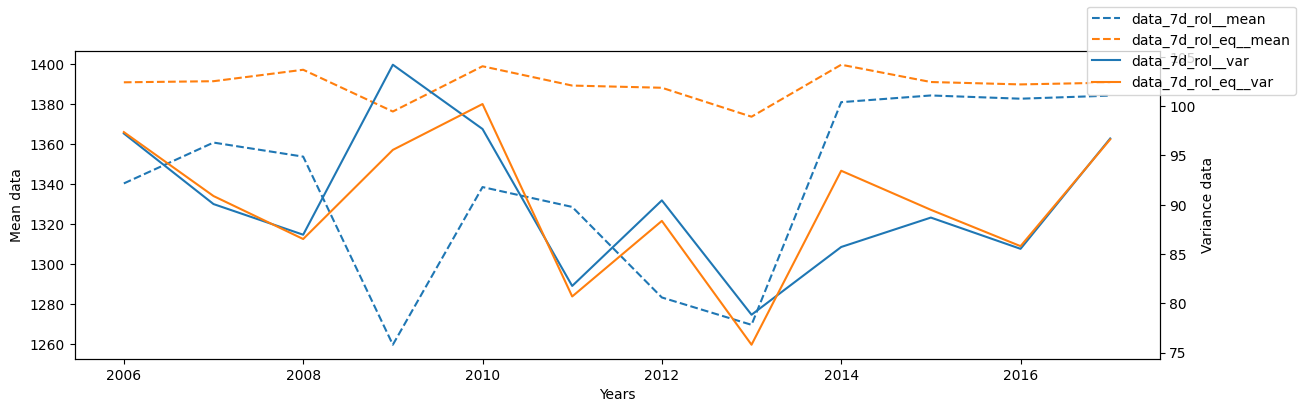

In [ ]:
# Создадим дф для хранения данных мат.ож. и дисперсии
aver_trends = pd.DataFrame(columns=['data_7d_rol__mean','data_7d_rol__var',
                                    'data_7d_rol_eq__mean', 'data_7d_rol_eq__var'], index=data_7d_rol.index.year.unique())

# Вычислим мат.ож и дисперсию для каждого года
for year in data_7d_rol.index.year.unique():

  aver_trends.loc[year]['data_7d_rol__mean'] = data_7d_rol['Consumption'][str(year)].mean()
  aver_trends.loc[year]['data_7d_rol__var'] = data_7d_rol['Consumption'][str(year)].std()
  aver_trends.loc[year]['data_7d_rol_eq__mean'] = data_correction['Consumption_eq_roll_7_day'][str(year)].mean()
  aver_trends.loc[year]['data_7d_rol_eq__var'] = data_correction['Consumption_eq_roll_7_day'][str(year)].std()

# Выведем результат на график с двуми осями
fig, ax1 = plt.subplots(figsize = (14,4))

ax2 = ax1.twinx()
ax1.plot(aver_trends['data_7d_rol__mean'], '--', label='data_7d_rol__mean')
ax1.plot(aver_trends['data_7d_rol_eq__mean'], '--', label='data_7d_rol_eq__mean')
ax2.plot(aver_trends['data_7d_rol__var'], label='data_7d_rol__var')
ax2.plot(aver_trends['data_7d_rol_eq__var'], label='data_7d_rol_eq__var')

ax1.set_xlabel('Years')
ax1.set_ylabel('Mean data')
ax2.set_ylabel('Variance data')
fig.legend()
plt.show()

## Функция генерирования дополнительных временных признаком
Функция генерирования дополнительных признаком для временного ряда средствами функции .dt, которая позволяет выделять временные диапазоны с различным шагом (час, день, неделя, месяц, квартал, год и т.д.)

In [ ]:
def Create_time_predictors(df):

	df['datetime'] = df.index # Копирование индексов дф в колонку
	df['hour'] = df.datetime.dt.hour # Час
	df['dayofweek'] = df.datetime.dt.dayofweek # День недели
	df['quarter'] = df.datetime.dt.quarter # Квартал
	df['month'] = df.datetime.dt.month # Месяц
	df['dayofyear'] = df.datetime.dt.dayofyear # День года
	df['day'] = df.datetime.dt.day # День
	df['weekofyear'] = df.datetime.dt.isocalendar().week # Неделя
	df = df.drop('datetime', axis = 1) # Удаление из дф колонки
	# Операция возвращения функцией дф
	return df

LR: 0.421818 (0.058571)
NN: 0.395710 (0.172083)
KNN: 0.673180 (0.159450)
RF: 0.848025 (0.021711)
SVR: 0.016285 (0.026550)


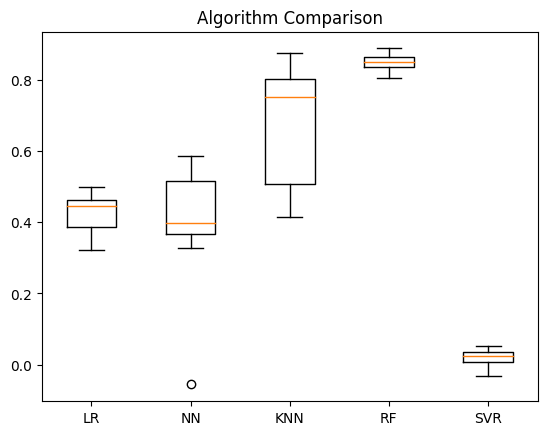

-------------------------------------------------------
LinearRegression()
r2:  0.4433
MAE:  98.5827
MSE:  15043.5814
RMSE:  122.6523


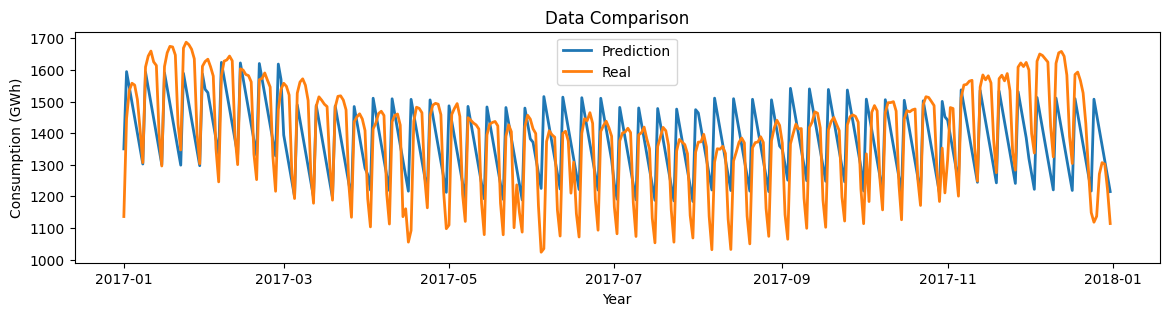

-------------------------------------------------------
MLPRegressor(learning_rate_init=0.1)
r2:  0.5182
MAE:  89.0636
MSE:  13018.6175
RMSE:  114.0992


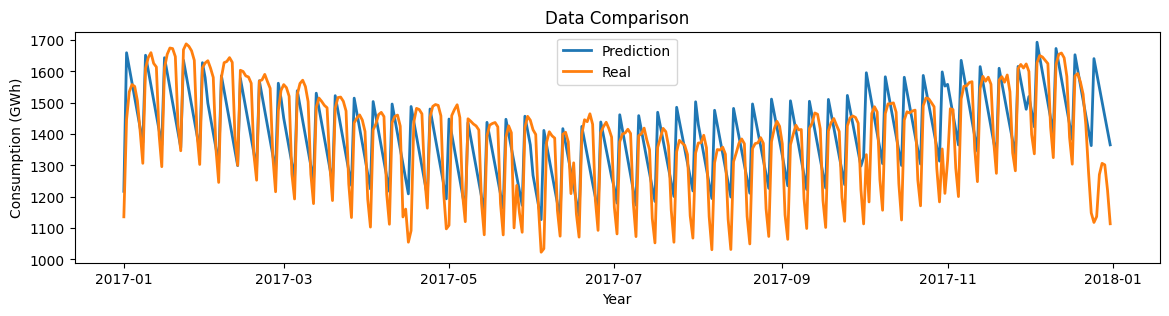

-------------------------------------------------------
KNeighborsRegressor()
r2:  0.8756
MAE:  39.9038
MSE:  3362.0734
RMSE:  57.9834


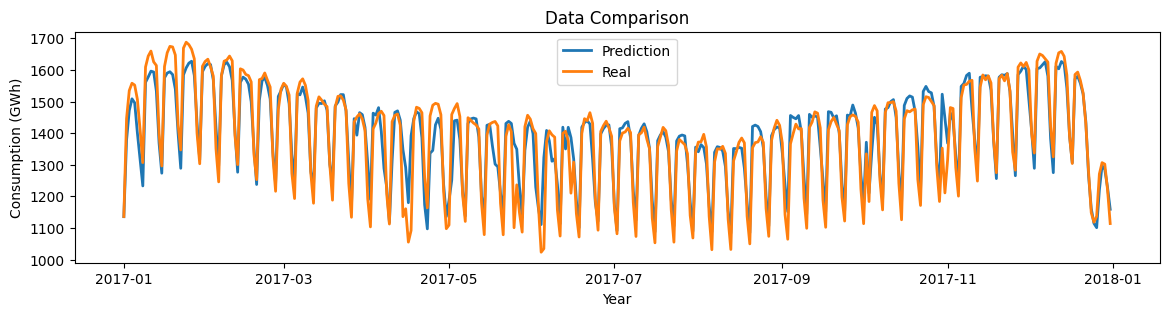

-------------------------------------------------------
RandomForestRegressor(n_estimators=50)
r2:  0.9369
MAE:  30.1116
MSE:  1704.8343
RMSE:  41.2896


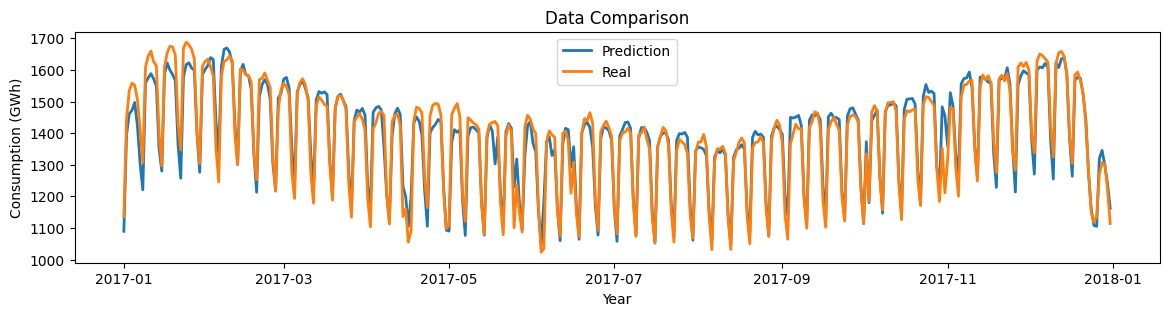

-------------------------------------------------------
SVR(gamma='auto')
r2:  0.0553
MAE:  122.7271
MSE:  25527.5474
RMSE:  159.7734


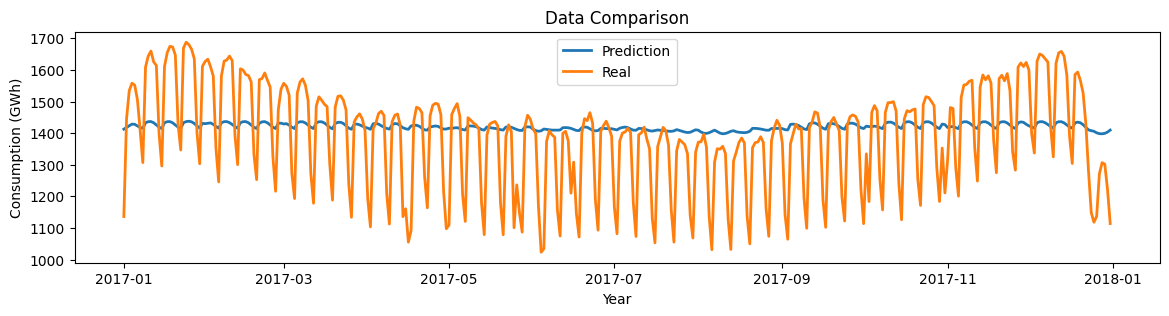

In [ ]:
import warnings
warnings.filterwarnings('ignore')

# Реализация прогнозирования на основе скорректированного датасета data_correction

# Формирмирование дополнительных временных признаков средствами функции Create_time_predictors()
data_correction = Create_time_predictors(data_correction)
# Удаление из дф неиспользуемых колонок
data_correction = data_correction.drop(['Consumption', 'Wind', 'Solar', 'Wind+Solar',
       'trend_residuals', 'trend_eq', 'Consumption_eq_roll_7_day', 'constant'], axis = 1)
data_correction = data_correction.dropna()


X_train = data_correction[:'2016'].drop(['Consumption_eq'], axis = 1)
y_train = data_correction.loc[:'2016', 'Consumption_eq']

X_test = data_correction['2017-01':'2017-12'].drop(['Consumption_eq'], axis = 1)
y_test = data_correction.loc['2017-01':'2017-12', 'Consumption_eq']

# Объявление алгоритмов МО и аккумуляция их в массив
# для удобной работы в цикле
models = [] # Лист для хранения моделей
models.append(('LR', LinearRegression()))
models.append(('NN', MLPRegressor(learning_rate_init = 0.1)))  # solver - определение ядра принятия решений
models.append(('KNN', KNeighborsRegressor()))
models.append(('RF', RandomForestRegressor(n_estimators = 50))) # n_estimators - число деревьев в ансамбле
models.append(('SVR', SVR(gamma='auto', kernel='rbf'))) # kernel - ядро по которому формируется опорный вектор
# Рассчетный цикл
results = [] # Лист для хранения результата оценки модели
names = [] # Лист для хранения имени модели
for name, model in models:
  # TimeSeriesSplit определяет количество частей на которые будет разбит датасет,
  # переменная tscv используется как атрибут функции cross_val_score(), т.е.
  # определяет количество частей датасета по которым будет проведен перекрестный
  # анализ (валидация результатов по метрике R^2)
  tscv = TimeSeriesSplit(n_splits=10)
  cv_results = cross_val_score(model, X_train, y_train, cv=tscv, scoring='r2')
  # Добавление результатов в лист results и names
  results.append(cv_results)
  names.append(name)
  # Вывод результатов
  print('%s: %f (%f)' % (name, cv_results.mean(), cv_results.std()))

# График сравнения используемых алгоритмов
plt.boxplot(results, labels=names)
plt.title('Algorithm Comparison')
plt.show()

# Цикл выполнения прогноза и сравнения реального временого хода
# со спрогнозированный результатом
for name, model in models:
  # Функция .fit() выполняет обучение модели (подгонку)
  # на основе тренировочного набора данных
  model = model.fit(X_train, y_train)
  # Функция .predict() выполняет прогнозирование
  # на основе тестового промежутка времени.
  y_pred = model.predict(X_test)
  # Далее выполняется передача результатов
  # прогнозирования y_pred и реального временного
  # хода y_test в функцию regression_results(), с целью
  # оценки точности итоговой модели.
  regression_results(y_test, y_pred, model)

  # Построение графика спрогнозированного и реальных временных ходов.
  fig, ax = plt.subplots(figsize = (14,3))
  ax.plot(X_test.index, y_pred, linewidth=2, label='Prediction')
  ax.plot(X_test.index, y_test, linewidth=2, label='Real')
  ax.set_title('Data Comparison')
  ax.legend()
  ax.set_xlabel('Year')
  ax.set_ylabel('Consumption (GWh)')
  plt.show()

Литература:

1) https://towardsdatascience.com/time-series-analysis-using-pandas-in-python-f726d87a97d8

2) https://towardsdatascience.com/time-series-modeling-using-scikit-pandas-and-numpy-682e3b8db8d1